In [ ]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from os import path
import os

# make the repo root importable so `utils` resolves from notebooks/
sys.path.insert(0, path.abspath(".."))
from utils import metrics
from utils import usage_profile as up


In [ ]:

SEED = 42

# Chart palette: fixed categorical order (never cycled), recessive ink/grid.
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
LIFT_CMAP = LinearSegmentedColormap.from_list("lift", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110,
})

# Dataset

In [3]:
import kagglehub
DATA_DIR = kagglehub.competition_download("nfl-big-data-bowl-2027")
DATA_DIR = path.join(DATA_DIR, "nfl-big-data-bowl-2027")

/home/arthur/miniconda3/envs/ml/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
players_df = pd.read_csv(path.join(DATA_DIR, 'players.csv'))
players_df =  players_df[players_df['nfl_position'] == 'WR']
players_df = players_df[['nfl_id', 'display_name', "draft_year"]]

In [5]:
career_df = pd.read_csv(path.join(DATA_DIR, 'player_career_successes.csv'))
players_df = players_df.merge(career_df, how='left', left_on='nfl_id', right_on='nfl_id')
players_df = players_df.drop(columns=['career_defensive_snaps', 'career_special_teams_snaps'])

In [6]:
plays_df = pd.read_csv(path.join(DATA_DIR, 'player_play.csv'))
plays_df = plays_df[plays_df['nfl_id'].isin(players_df['nfl_id'])]
plays_df = plays_df[[
    "game_id", "play_id", "nfl_id", # identifiers
    "quarter", "down", "yards_to_go", "yardline_number", "game_clock", # game context
    "offense_formation", "receiver_alignment", "lined_up_position", "route_ran", "in_motion_at_ball_snap",  # offesive context
    "team_coverage_man_zone", "team_coverage_type", # defensive context
    "pass_result", "play_nullified_by_penalty", "pass_length", "yards_gained", "expected_points_added", # play result
    "target", "rec_yards", "yards_after_catch", "separation_at_pass_forward", "cushion", "expected_yards_after_catch" # receiver result
]]
plays_df = plays_df[plays_df['play_nullified_by_penalty'] == "N"].drop(columns=['play_nullified_by_penalty'])

In [7]:
games_df = pd.read_csv(path.join(DATA_DIR, 'games.csv'))

In [8]:
len(players_df), len(plays_df)

(106, 42806)

# Player Usage Profile

**Question:** *how* is each receiver used? Before judging how well a receiver plays, we want to know what job he is asked to do. A 4-yard aDOT slot receiver and a 16-yard aDOT outside "X" should not be compared directly.

We describe usage with three things:

| Feature | What it captures |
|---|---|
| **Route distribution** | the share of routes that are GO, HITCH, CROSS, SCREEN, ... |
| **slot%** | how often he lines up in the slot (`lined_up_position == "SLOT_WR"`) |
| **aDOT** | how far downfield he is targeted (average `pass_length` on targets) |

Then we cluster player-seasons on those features. The analysis has four steps:

1. Give each play its **season**, so that the unit of analysis is a *player-season*.
2. Build `usage_profile_df`, with one row per player-season.
3. Make the features **statistically sound**: a minimum sample, shrinkage, and the right transforms.
4. **Cluster**, then interpret the clusters through their centroids and the players closest to them.

## 1. Season assignment

A receiver's role can change a lot from one year to the next: a new team, a new coordinator, a promotion from WR3 to WR1. If we pooled all seasons, a player who was a slot receiver in 2023 and an outside X in 2025 would look like an average of the two roles, which he never actually played. So **each player-season gets its own profile.**

`games.csv` maps each `game_id` to a `season`. Postseason games are kept and count toward the season they belong to.

In [9]:
plays_df = plays_df.merge(
    games_df[["game_id", "season"]], on="game_id", how="left", validate="many_to_one"
)
assert plays_df["season"].notna().all(), "every play must map to a season"

plays_df.groupby("season").size().rename("plays")

season
2023     9186
2024    14782
2025    18838
Name: plays, dtype: int64

## 2. `usage_profile_df`: one row per player-season

For each `(nfl_id, season)` we store:

- **`routes_run`** and the **raw count of each route**. We keep counts, not just shares, because the next step needs to know *how much evidence* is behind each share.
- **`slot_routes` / `slot_pct`**: routes run from the slot ÷ all routes.
- **`targets_with_depth` / `adot`**: the average depth of target, and how many targets it is based on.

In [10]:
KEY = ["nfl_id", "season"]

raw_route_counts = up.route_counts(plays_df.assign(route=plays_df["route_ran"]), by=KEY)
slot = metrics.slot_rate(plays_df, by=KEY)
adot = metrics.average_depth_of_target(plays_df, by=KEY)

usage_profile_df = (
    raw_route_counts.add_prefix("n_")
    .join(slot[["routes_run", "slot_routes", "slot_pct"]])
    .join(adot[["targets_with_depth", "adot"]])
    .join(players_df.set_index("nfl_id")["display_name"], on="nfl_id")
)
usage_profile_df["targets_with_depth"] = usage_profile_df["targets_with_depth"].fillna(0).astype(int)

assert usage_profile_df["routes_run"].sum() == plays_df["route_ran"].notna().sum()
assert usage_profile_df["slot_pct"].between(0, 1).all()
print(f"{len(usage_profile_df)} player-seasons")
usage_profile_df.head()

196 player-seasons


n_ANGLE  n_CORNER  n_CROSS  n_FLAT  n_GO  n_HITCH  n_IN  n_OUT  \
nfl_id season                                                                   
55884  2023          0        34       82      22    55       73    45     68   
       2024          2        63       94      19   102      114    39     71   
       2025          7        57       70      17    83       64    52     69   
55885  2023          0        45       52       4   133       87    27     20   
       2024          0        24       65       3   125       87    30     30   

               n_POST  n_SCREEN  n_SLANT  n_WHEEL  routes_run  slot_routes  \
nfl_id season                                                                
55884  2023        27        30       34        1         471          314   
       2024        41        24       31        0         600          494   
       2025        73        20       49        6         567          136   
55885  2023        67        14       43        0         492           53   
       2024        32        12       30        0         438           58   

               slot_pct  targets_with_depth       adot        display_name  
nfl_id season                                                               
55884  2023    0.666667                 100   6.330000  Jaxon Smith-Njigba  
       2024    0.823333                 139   8.741007  Jaxon Smith-Njigba  
       2025    0.239859                 190  11.000000  Jaxon Smith-Njigba  
55885  2023    0.107724                  78  12.487179    Quentin Johnston  
       2024    0.132420                  98  11.397959    Quentin Johnston

Volume varies hugely. Some player-seasons have a handful of routes, others have more than 600. That is the main threat to statistical correctness, and it is what step 3 deals with.

In [11]:
usage_profile_df[["routes_run", "targets_with_depth"]].describe().round(1)

,routes_run,targets_with_depth
count,196.0,196.0
mean,218.4,41.3
std,182.7,40.1
min,1.0,0.0
25%,52.8,10.0
50%,172.0,26.0
75%,342.8,64.2
max,656.0,208.0


## 3. Statistical correctness

Clustering on raw shares would mostly find *noise*. A player with 30 routes who happened to run 6 slants would look like a "slant specialist". We fix this in seven small steps:

| Step | Problem | Fix |
|---|---|---|
| 3.1 | rare routes make near-empty dimensions | collapse WHEEL + ANGLE into FLAT |
| 3.2 | tiny samples are too noisy to profile | minimum-routes floor, chosen by bootstrap |
| 3.3 | moderate samples are still noisy, and contain zeros | Dirichlet shrinkage toward the league mix |
| 3.4 | shares are *compositional* (they sum to 1) | centered log-ratio (CLR) transform + PCA |
| 3.5 | slot% is noisy for small samples, and bounded in [0, 1] | beta shrinkage + logit |
| 3.6 | aDOT is based on *targets*, far fewer than routes | shrinkage using its stabilization constant k |
| 3.7 | the features are on different scales | standardize + weight the blocks |

### 3.1 Collapse rare routes

WHEEL and ANGLE are rare for wide receivers (they are mostly running-back routes). As separate columns they would be almost all zeros, and after the log transform those zeros turn into extreme values that dominate the distance between players. Both are short releases toward the sideline, so we pool them with FLAT.

In [12]:
plays_df["route"] = up.collapse_routes(plays_df["route_ran"])
route_counts = up.route_counts(plays_df, by=KEY)
ROUTES = list(route_counts.columns)

route_counts.sum().sort_values(ascending=False).rename("routes (all WR player-seasons)")

GO            8533
HITCH         6980
CROSS         5374
IN            4829
POST          4310
OUT           4141
CORNER        3427
SLANT         2850
FLAT_WHEEL    1193
SCREEN        1169
Name: routes (all WR player-seasons), dtype: int64

### 3.2 Minimum-routes floor

How many routes do we need before a route mix is trustworthy? We answer this with a **bootstrap** instead of picking a round number:

1. Take every high-volume player-season (≥ 400 routes) and treat its full route mix as the "truth".
2. Draw *n* routes from that mix, many times over.
3. Measure the **total variation distance** (TVD) between the sampled and true mix. TVD is the share of routes you would have to re-label to turn one distribution into the other.

The floor is the smallest *n* where the **median TVD ≤ 0.10**, i.e. a typical sample mislabels less than 10% of the player's route tree. Player-seasons below the floor stay in `usage_profile_df` with `qualified = False`, but they are **not used to fit** anything.

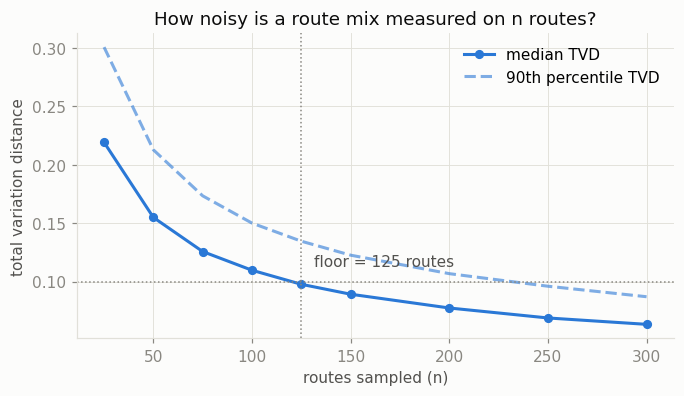

floor = 125 routes -> 110 of 196 player-seasons qualify


In [13]:
ROUTE_FLOOR, floor_curve = up.choose_route_floor(route_counts, tol=0.10, seed=SEED)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(floor_curve["n_routes"], floor_curve["median_tvd"], color=CATEGORICAL[0], lw=2, marker="o", ms=5, label="median TVD")
ax.plot(floor_curve["n_routes"], floor_curve["p90_tvd"], color=CATEGORICAL[0], lw=2, ls="--", alpha=0.6, label="90th percentile TVD")
ax.axhline(0.10, color=MUTED, lw=1, ls=":")
ax.axvline(ROUTE_FLOOR, color=MUTED, lw=1, ls=":")
ax.annotate(f"floor = {ROUTE_FLOOR} routes", (ROUTE_FLOOR, 0.10), xytext=(8, 10), textcoords="offset points", color=INK_2)
ax.set(xlabel="routes sampled (n)", ylabel="total variation distance", title="How noisy is a route mix measured on n routes?")
ax.legend(frameon=False)
plt.show()

usage_profile_df["qualified"] = usage_profile_df["routes_run"] >= ROUTE_FLOOR
print(f"floor = {ROUTE_FLOOR} routes -> {usage_profile_df['qualified'].sum()} of {len(usage_profile_df)} player-seasons qualify")

### 3.3 Dirichlet shrinkage of the route mix

Even above the floor, a 150-route season is noisier than a 600-route season. Shrinkage blends each player's own mix with the league mix, in proportion to how little data he has:

$$\hat{p}_{ij} = \frac{\text{count}_{ij} + \alpha \cdot \pi_j}{n_i + \alpha}$$

- $\pi_j$ is the league share of route *j*.
- $\alpha$ works like **"pseudo-routes" of league-average behaviour**. A player with $n = \alpha$ routes ends up halfway between his own mix and the league's. With $n \gg \alpha$, his own mix dominates.
- $\alpha$ is **estimated from the data** by method of moments (Dirichlet-multinomial). We compare how spread out the observed mixes are with how spread out they *would* be from sampling noise alone. The difference is real between-player differences.

A useful side effect: no share is exactly 0 after shrinkage, which the log-ratio transform in 3.4 needs.

In [14]:
q = usage_profile_df["qualified"]
ROUTE_ALPHA, league_route_mix = up.estimate_dirichlet_alpha(route_counts[q])
shrunk_shares = up.shrink_composition(route_counts, ROUTE_ALPHA, league_route_mix)

assert np.allclose(shrunk_shares.sum(axis=1), 1) and (shrunk_shares > 0).all().all()
print(f"alpha = {ROUTE_ALPHA:.1f} pseudo-routes")

pd.DataFrame({
    "league share": league_route_mix,
    "raw share (example)": up._shares(route_counts).loc[q].iloc[-1],
    "shrunk share (example)": shrunk_shares.loc[q].iloc[-1],
}).round(3)

alpha = 73.7 pseudo-routes


,league share,raw share (example),shrunk share (example)
CORNER,0.081,0.076,0.077
CROSS,0.126,0.124,0.124
FLAT_WHEEL,0.029,0.015,0.017
GO,0.195,0.274,0.260
HITCH,0.162,0.135,0.140
IN,0.114,0.106,0.107
OUT,0.098,0.068,0.073
POST,0.102,0.150,0.141
SCREEN,0.027,0.029,0.029
SLANT,0.066,0.024,0.031


### 3.4 Compositional data: CLR + PCA

Route shares are **compositional**: they sum to 1, so they aren't independent. If one share goes up, others must go down. Euclidean distance on raw shares also treats a 1% → 3% change (tripling a route) as smaller than a 30% → 33% change (a slight tweak). For usage, the first change matters more.

The **centered log-ratio** transform fixes both problems:

$$\text{clr}(p)_j = \log p_j - \frac{1}{J}\sum_k \log p_k$$

It moves the shares into ordinary Euclidean space, where distances reflect *relative* differences. The CLR columns still add up to 0, so one dimension is redundant. We then apply **PCA**, keeping 90% of the variance: this removes the redundant dimension, and the small, noisy directions with it. We don't z-score the CLR columns, because that would inflate the rarest routes back up.

In [15]:
route_clr = up.clr(shrunk_shares)
route_clr.loc[q].describe().loc[["mean", "std"]].round(2)

,CORNER,CROSS,FLAT_WHEEL,GO,HITCH,IN,OUT,POST,SCREEN,SLANT
mean,0.01,0.43,-1.16,0.90,0.70,0.32,0.15,0.24,-1.35,-0.24
std,0.32,0.23,0.57,0.36,0.24,0.35,0.29,0.28,0.69,0.37


### 3.5 slot%: beta shrinkage + logit

slot% is a success rate (slot routes ÷ routes), so it gets the two-category version of 3.3, a **beta-binomial** shrinkage toward the league slot rate with an estimated prior strength. Then we apply a **logit** transform. Moving from 2% to 10% slot is a bigger change in role than moving from 46% to 54%, and logit spreads out the ends of the [0, 1] range to match.

In [16]:
slot_counts = pd.DataFrame({
    "slot": usage_profile_df["slot_routes"],
    "wide": usage_profile_df["routes_run"] - usage_profile_df["slot_routes"],
})
SLOT_ALPHA, slot_prior = up.estimate_dirichlet_alpha(slot_counts[q])
usage_profile_df["slot_pct_shrunk"] = up.shrink_composition(slot_counts, SLOT_ALPHA, slot_prior)["slot"]

print(f"league slot% = {slot_prior['slot']:.1%}, prior strength = {SLOT_ALPHA:.1f} pseudo-routes")

league slot% = 34.7%, prior strength = 6.4 pseudo-routes


### 3.6 aDOT: shrinkage using its stabilization constant

aDOT is averaged over **targets**, not routes, so a 150-route season may have only ~25 targets behind it. We use the same idea from the lesson on minimum samples:

$$k = \frac{\sigma^2_{\text{within}}}{\tau^2_{\text{between}}}, \qquad \widehat{\text{aDOT}}_i = \frac{n_i \cdot \text{aDOT}_i + k \cdot \mu}{n_i + k}$$

$\sigma^2_{\text{within}}$ is how much target depth varies *for the same player*, and $\tau^2_{\text{between}}$ is how much true aDOT varies *between players*. $k$ is the number of targets at which a player's aDOT is half signal and half noise.

In [17]:
targets = plays_df[(plays_df["target"] == True) & plays_df["pass_length"].notna()]
in_q = pd.MultiIndex.from_frame(targets[KEY]).isin(usage_profile_df.index[q])
player_season = targets["nfl_id"].astype(str) + "-" + targets["season"].astype(str)

ADOT_K = up.stabilization_k(targets.loc[in_q, "pass_length"], player_season[in_q])
ADOT_PRIOR = targets.loc[in_q, "pass_length"].mean()
usage_profile_df["adot_shrunk"] = up.shrink_mean(
    usage_profile_df["adot"], usage_profile_df["targets_with_depth"], ADOT_K, ADOT_PRIOR
)
print(f"league aDOT = {ADOT_PRIOR:.1f} yds, k = {ADOT_K:.1f} targets")
usage_profile_df.loc[q, ["targets_with_depth", "adot", "adot_shrunk"]].describe().round(1)

league aDOT = 11.0 yds, k = 18.1 targets


,targets_with_depth,adot,adot_shrunk
count,110.0,110.0,110.0
mean,66.1,11.3,11.2
std,37.7,3.2,2.3
min,13.0,4.0,5.2
25%,37.0,9.3,9.9
50%,59.5,11.2,11.1
75%,83.8,13.4,12.6
max,208.0,20.0,17.1


### 3.7 Feature matrix: scaling and block weights

KMeans uses Euclidean distance, so every feature has to be on a comparable scale, and we have to decide **how much each block counts**:

- `slot_z`: logit(slot%), z-scored (variance 1)
- `adot_z`: aDOT, z-scored (variance 1)
- `route_pc*`: the PCA scores of the route mix, rescaled together so the **whole block has total variance `ROUTE_WEIGHT`**

With `ROUTE_WEIGHT = 2`, the route tree counts as much as slot% and aDOT combined. Without this rescaling, the route block would get one "vote" per principal component and drown out the other two features. `ROUTE_WEIGHT` is an analyst choice: raise it to make profiles more about route trees, lower it to make them more about alignment and depth.

All parameters (PCA, means, standard deviations) are fit on **qualified** player-seasons only.

In [18]:
ROUTE_WEIGHT = 2.0

fit_df = usage_profile_df[q]
features = up.UsageFeatures(route_weight=ROUTE_WEIGHT, pca_variance=0.90, seed=SEED)
X = features.fit_transform(shrunk_shares.loc[q], fit_df["slot_pct_shrunk"], fit_df["adot_shrunk"])

print(f"route block: {features.pca.n_components_} PCs, "
      f"{features.pca.explained_variance_ratio_.sum():.0%} of CLR variance")
X.var(ddof=0).round(2)

route block: 6 PCs, 91% of CLR variance


route_pc1    0.96
route_pc2    0.41
route_pc3    0.25
route_pc4    0.19
route_pc5    0.10
route_pc6    0.08
slot_z       1.00
adot_z       1.00
dtype: float64

## 4. Clustering

We use **KMeans** with many random restarts (`n_init=50`) and a fixed seed, so the result is reproducible.

To choose the number of profiles **K**, we look at two curves:

- **Inertia (elbow):** total within-cluster distance. It always goes down as K grows, so we look for the point where adding a cluster stops helping much.
- **Silhouette:** how much closer each point is to its own cluster than to the next nearest one (from −1 to 1, higher is better).

These curves only help us choose K. The final choice also depends on whether the profiles make football sense (section 5).

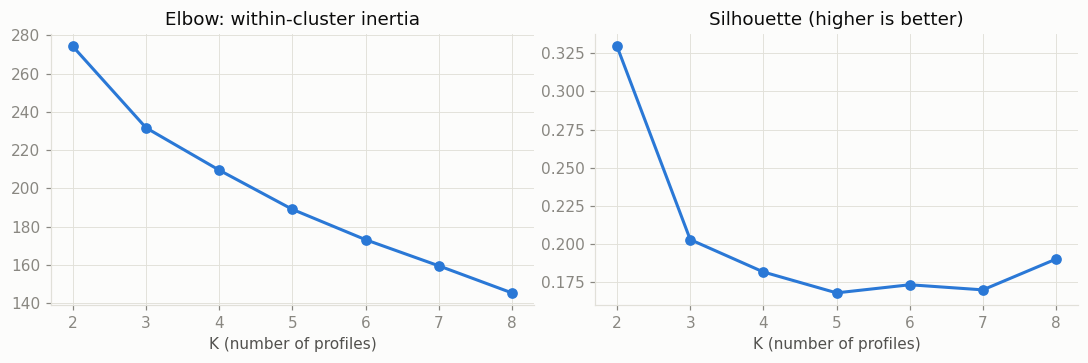

,k,inertia,silhouette
0,2,274.243,0.329
1,3,231.717,0.203
2,4,209.584,0.182
3,5,189.083,0.168
4,6,173.221,0.174
5,7,159.577,0.170
6,8,145.411,0.190


In [19]:
k_range = range(2, 9)
scan = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    scan.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
scan = pd.DataFrame(scan)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col, title in zip(axes, ["inertia", "silhouette"], ["Elbow: within-cluster inertia", "Silhouette (higher is better)"]):
    ax.plot(scan["k"], scan[col], color=CATEGORICAL[0], lw=2, marker="o", ms=6)
    ax.set(xlabel="K (number of profiles)", title=title)
plt.tight_layout()
plt.show()
scan.round(3)

**Choosing K.** The silhouette is highest at K = 2, but that split is just "slot vs. outside", which we already know from slot% alone. Beyond K = 2, the silhouette is flat (~0.17–0.20) and the elbow has no sharp bend. That tells us **WR usage is a continuum, not a set of well-separated groups**: the profiles are useful landmarks on that continuum, not hard categories.

We use **K = 4**. It is the smallest K that splits outside receivers into vertical and intermediate roles, and slot receivers into a "big slot" and an underneath/gadget role, while every profile keeps 19+ player-seasons.

In [20]:
K = 4

kmeans = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
usage_profile_df["usage_profile"] = pd.Series(kmeans.labels_, index=X.index)
usage_profile_df["usage_profile"] = usage_profile_df["usage_profile"].astype("Int64")

usage_profile_df.loc[q, "usage_profile"].value_counts().sort_index().rename("player-seasons")

usage_profile
0    33
1    19
2    33
3    25
Name: player-seasons, dtype: Int64

## 5. Human interpretation

A cluster is only useful if we can describe it in football terms. We look at it three ways:

1. **Centroids in readable units.** Each KMeans centroid is mapped back from feature space to route shares, slot% and aDOT (inverse PCA → inverse CLR, inverse logit, un-scaling).
2. **Route lift vs. league:** centroid share ÷ league share. A lift of 2.0 on SCREEN means this profile runs twice as many screens as the average WR.
3. **The 3 player-seasons closest to each centroid**: the most typical examples of each profile.

In [21]:
centroids = features.inverse_transform(kmeans.cluster_centers_)
centroids.index.name = "usage_profile"
centroids["size"] = usage_profile_df.loc[q, "usage_profile"].value_counts().sort_index()

centroid_table = centroids.copy()
centroid_table[ROUTES] = (centroid_table[ROUTES] * 100).round(1)
centroid_table["slot_pct"] = (centroid_table["slot_pct"] * 100).round(1)
centroid_table["adot"] = centroid_table["adot"].round(1)
print("Centroids (route shares and slot% in %, aDOT in yards)")
centroid_table

Centroids (route shares and slot% in %, aDOT in yards)


,CORNER,CROSS,FLAT_WHEEL,GO,HITCH,IN,OUT,POST,SCREEN,SLANT,slot_pct,adot,size
usage_profile,,,,,,,,,,,,,
0,8.8,12.1,1.6,22.5,16.1,10.6,9.2,11.0,2.5,5.6,22.9,12.2,33
1,9.0,11.0,1.6,24.1,16.6,12.5,7.4,11.2,0.9,5.8,19.0,14.0,19
2,7.9,12.0,3.1,18.8,17.0,12.5,10.2,9.3,1.4,7.7,35.5,10.6,33
3,7.1,15.1,5.2,15.7,15.4,9.4,10.7,10.0,5.3,6.2,55.7,8.5,25


In [22]:
route_lift = centroids[ROUTES].div(league_route_mix[ROUTES], axis=1)
route_lift.round(2)

,CORNER,CROSS,FLAT_WHEEL,GO,HITCH,IN,OUT,POST,SCREEN,SLANT
usage_profile,,,,,,,,,,
0,1.08,0.96,0.56,1.16,1.00,0.93,0.94,1.08,0.93,0.85
1,1.11,0.87,0.54,1.23,1.02,1.09,0.76,1.10,0.34,0.88
2,0.97,0.95,1.09,0.97,1.05,1.09,1.04,0.91,0.54,1.17
3,0.87,1.20,1.79,0.80,0.95,0.82,1.09,0.98,1.97,0.95


In [24]:
nearest = up.nearest_to_centroids(X, kmeans.labels_, kmeans.cluster_centers_, n=5)
nearest = nearest.join(usage_profile_df[["display_name", "routes_run", "slot_pct", "adot", "targets_with_depth"]])
nearest["slot_pct"] = (nearest["slot_pct"] * 100).round(1)
nearest[["distance", "adot"]] = nearest[["distance", "adot"]].round(2)
nearest.reset_index().set_index(["cluster", "display_name", "season"])[["routes_run", "slot_pct", "adot", "targets_with_depth", "distance"]]

routes_run  slot_pct   adot  \
cluster display_name      season                                
0       Ronnie Bell       2023           132      24.2  12.00   
        Trey Palmer       2024           179      24.6  13.71   
        Tank Dell         2023           323      26.3  14.11   
        Jonathan Mingo    2023           546      31.0  10.78   
        Tank Dell         2024           440      25.0  12.38   
1       Adonai Mitchell   2025           345      19.1  14.89   
        Jalen Brooks      2024           216      17.1  14.06   
        Ricky Pearsall    2025           306      17.0  13.78   
        Elic Ayomanor     2025           485      17.7  12.47   
        Isaac TeSlaa      2025           333      24.0  13.00   
2       Ryan Flournoy     2025           309      30.7  10.09   
        Jalen Brooks      2025           126      34.1  11.08   
        Xavier Hutchinson 2023           218      32.1   9.79   
        Michael Wilson    2024           481      34.3  11.34   
        Malik Heath       2023           173      22.5  10.38   
3       Jimmy Horn        2025           130      59.2   6.79   
        Luther Burden     2025           341      43.1   8.24   
        Jaylin Noel       2025           230      56.5   9.10   
        Malik Washington  2024           269      48.0   6.70   
        Demario Douglas   2023           320      62.2   8.04   

                                  targets_with_depth  distance  
cluster display_name      season                                
0       Ronnie Bell       2023                    28      0.53  
        Trey Palmer       2024                    24      0.74  
        Tank Dell         2023                    84      0.80  
        Jonathan Mingo    2023                    89      0.93  
        Tank Dell         2024                    82      0.94  
1       Adonai Mitchell   2025                    82      0.77  
        Jalen Brooks      2024                    33      0.96  
        Ricky Pearsall    2025                    59      0.98  
        Elic Ayomanor     2025                    98      1.04  
        Isaac TeSlaa      2025                    40      1.07  
2       Ryan Flournoy     2025                    69      0.54  
        Jalen Brooks      2025                    13      0.68  
        Xavier Hutchinson 2023                    33      0.74  
        Michael Wilson    2024                    71      0.79  
        Malik Heath       2023                    40      0.91  
3       Jimmy Horn        2025                    24      0.81  
        Luther Burden     2025                    80      0.90  
        Jaylin Noel       2025                    41      0.95  
        Malik Washington  2024                    43      0.99  
        Demario Douglas   2023                    81      1.01

### Visualizations

**Route lift heatmap.** Each row is a profile and each column a route. Red means the profile runs that route more than the league average, blue means less, and gray means about average. The color scale is logarithmic, so 2× and 0.5× are equally strong.

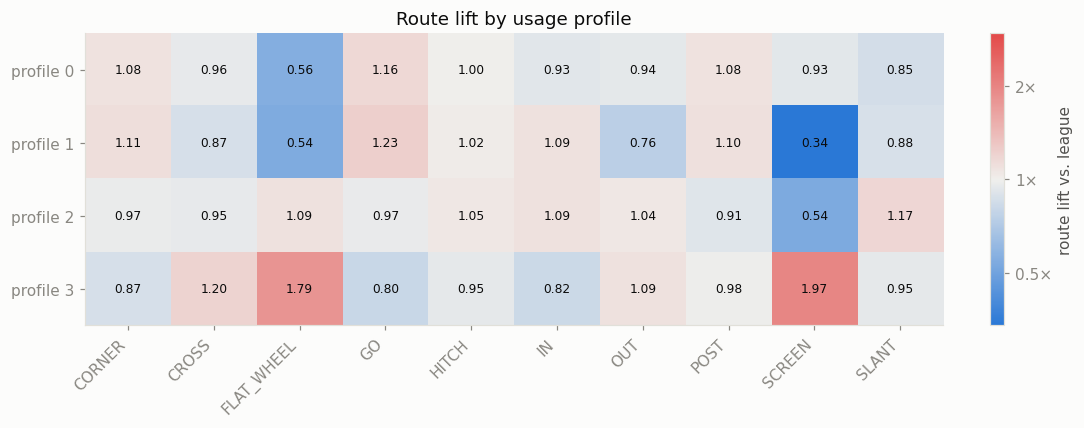

In [25]:
log_lift = np.log2(route_lift)
lim = np.abs(log_lift.to_numpy()).max()
fig, ax = plt.subplots(figsize=(10, 0.6 * K + 1.6))
im = ax.imshow(log_lift, cmap=LIFT_CMAP, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(ROUTES)), ROUTES, rotation=45, ha="right")
ax.set_yticks(range(K), [f"profile {i}" for i in range(K)])
ax.grid(False)
for i in range(K):
    for j in range(len(ROUTES)):
        ax.text(j, i, f"{route_lift.iat[i, j]:.2f}", ha="center", va="center", fontsize=8, color=INK)
cbar = fig.colorbar(im, ax=ax, fraction=0.03)
ticks = np.array([-2, -1, 0, 1, 2])
ticks = ticks[np.abs(ticks) <= lim]
cbar.set_ticks(ticks, labels=[f"{2.0 ** t:g}×" for t in ticks])
cbar.set_label("route lift vs. league", color=INK_2)
ax.set_title("Route lift by usage profile")
plt.tight_layout()
plt.show()

**slot% vs. aDOT.** These two features are directly interpretable, so this scatter shows the profiles on football axes. Large markers are the centroids, and the labelled points are the 3 player-seasons closest to each centroid.

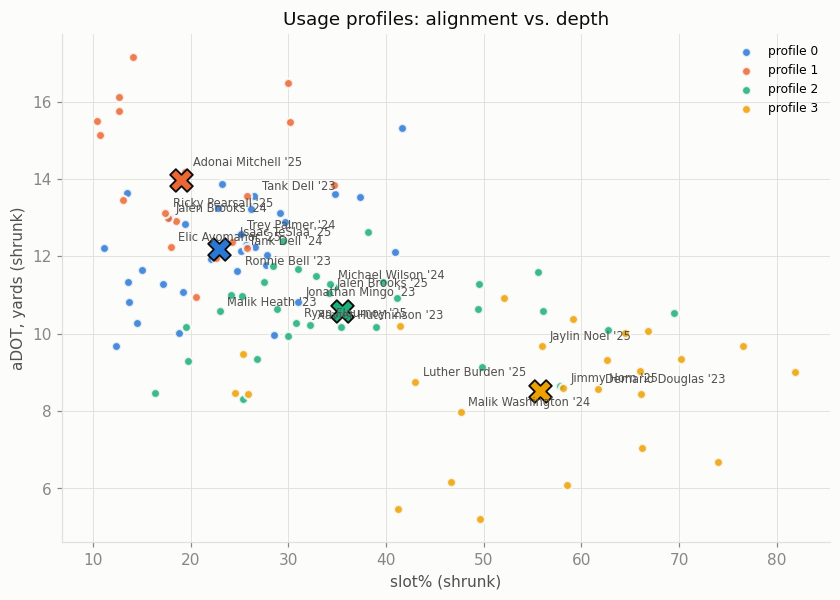

In [26]:
def scatter_profiles(ax, xy, centers_xy, xlabel, ylabel, title):
    labels = usage_profile_df.loc[q, "usage_profile"].to_numpy()
    for c in range(K):
        m = labels == c
        ax.scatter(xy[m, 0], xy[m, 1], s=36, color=CATEGORICAL[c], edgecolor=SURFACE, linewidth=1.5,
                   alpha=0.85, label=f"profile {c}", zorder=2)
        ax.scatter(*centers_xy[c], s=220, marker="X", color=CATEGORICAL[c], edgecolor=INK, linewidth=1.2, zorder=4)
    pos = {key: i for i, key in enumerate(X.index)}
    for key, row in nearest.iterrows():
        x, y = xy[pos[key]]
        ax.annotate(f"{row['display_name']} '{str(key[1])[2:]}", (x, y), xytext=(5, 4), textcoords="offset points",
                    fontsize=7.5, color=INK_2, zorder=5)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend(frameon=False, fontsize=8, loc="best")

fig, ax = plt.subplots(figsize=(9, 6))
xy = np.column_stack([fit_df["slot_pct_shrunk"] * 100, fit_df["adot_shrunk"]])
centers_xy = centroids[["slot_pct", "adot"]].to_numpy() * [100, 1]
scatter_profiles(ax, xy, centers_xy, "slot% (shrunk)", "aDOT, yards (shrunk)", "Usage profiles: alignment vs. depth")
plt.show()

**Route-mix PCA.** This plots the first two principal components of the route mix (CLR space), the same space the route block of the clustering uses. The arrows show which routes pull a player in each direction.

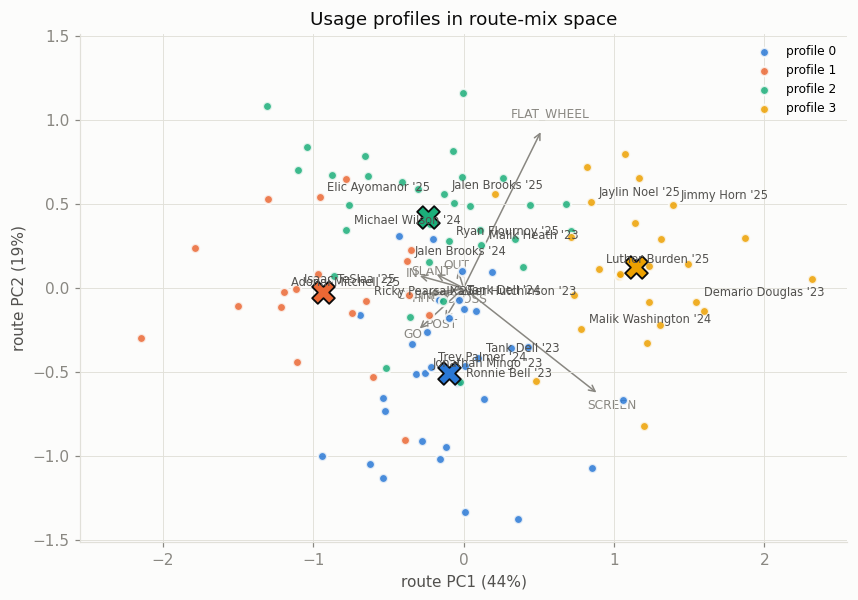

In [27]:
pcs = features.pca.transform(route_clr.loc[q].to_numpy())[:, :2]
center_pcs = kmeans.cluster_centers_[:, :2] / features.route_scale

fig, ax = plt.subplots(figsize=(9, 6))
evr = features.pca.explained_variance_ratio_
scatter_profiles(ax, pcs, center_pcs, f"route PC1 ({evr[0]:.0%})", f"route PC2 ({evr[1]:.0%})", "Usage profiles in route-mix space")

loadings = features.pca.components_[:2].T
extent = np.abs(pcs).max(axis=0)
scale = 0.8 * extent.min() / np.linalg.norm(loadings, axis=1).max()
for route, (lx, ly) in zip(ROUTES, loadings):
    ax.annotate("", xy=(lx * scale, ly * scale), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=MUTED, lw=1), zorder=1)
    ax.text(lx * scale * 1.1, ly * scale * 1.1, route, fontsize=8, color=MUTED, ha="center", va="center", zorder=1)
ax.set(xlim=(-extent[0] * 1.1, extent[0] * 1.1), ylim=(-extent[1] * 1.1, extent[1] * 1.1))
plt.show()

### Profile descriptions

Draft names based on the centroid table, route lift heatmap and closest players (K = 4, fit on qualified player-seasons):

| Profile | Name | Centroid | Signature routes (lift vs. league) | Typical player-seasons |
|---|---|---|---|---|
| 0 | **Outside intermediate** | 23% slot, 12.2 aDOT | balanced tree with a slight downfield tilt: GO 1.16, CORNER 1.08, POST 1.08; few FLAT/WHEEL (0.56) | Ronnie Bell '23, Trey Palmer '24, Tank Dell '23 |
| 1 | **Vertical outside X** | 19% slot, 14.0 aDOT | GO 1.23, CORNER 1.11, POST 1.10, IN 1.09; almost no SCREEN (0.34), few OUT (0.76) | Adonai Mitchell '25, Jalen Brooks '24, Ricky Pearsall '25 |
| 2 | **Big slot / inside breaker** | 36% slot, 10.6 aDOT | SLANT 1.17, IN 1.09, FLAT/WHEEL 1.09; few SCREEN (0.54) | Ryan Flournoy '25, Jalen Brooks '25, Xavier Hutchinson '23 |
| 3 | **Slot underneath / gadget** | 56% slot, 8.5 aDOT | SCREEN 1.97, FLAT/WHEEL 1.79, CROSS 1.20; fewer GO (0.80) and IN (0.82) | Jimmy Horn '25, Luther Burden '25, Jaylin Noel '25 |

Remarks:
- The main axis of WR usage is **depth + alignment**: from outside vertical (profile 1) to slot underneath (profile 3). Route PC1 lines up with SCREEN vs. GO/CORNER/POST.
- Profiles 0 and 1 overlap the most. They differ mainly in depth (aDOT 12 vs. 14) and in how often they run screens and outs.
- The same player can change profile between seasons (e.g. Jalen Brooks: profile 1 in 2024, profile 2 in 2025). This is the reason profiles are assigned per season.
- Player-seasons below the floor (`qualified == False`) have no profile (`<NA>`). They can be assigned to the nearest centroid later, flagged as low-confidence.

In [28]:
usage_profile_df.loc[q].groupby("usage_profile")[["routes_run", "slot_pct", "adot"]].mean().round(2)

,routes_run,slot_pct,adot
usage_profile,,,
0,363.88,0.24,12.60
1,348.42,0.20,15.19
2,347.12,0.36,10.40
3,329.76,0.56,7.79


# Save Profiles

In [ ]:
import json
import joblib
import sklearn

OUT_DIR = path.abspath("../data/processed/usage_profile")
os.makedirs(OUT_DIR, exist_ok=True)   # needs `import os`

# 1. Player-season profiles (all 196 rows; unqualified ones have usage_profile = <NA>)
usage_profile_df.to_parquet(path.join(OUT_DIR, "usage_profile_df.parquet"))

# 2. Centroids in readable units, plus route lift
centroids.to_parquet(path.join(OUT_DIR, "centroids.parquet"))
centroids.round(4).to_csv(path.join(OUT_DIR, "centroids.csv"))
route_lift.round(4).to_csv(path.join(OUT_DIR, "route_lift.csv"))

# 3. Fitted pipeline: everything needed to place a new player-season in the same space
joblib.dump(
    {
        "features": features,              # PCA + scalers (UsageFeatures)
        "kmeans": kmeans,                  # cluster_centers_ live in feature space
        "league_route_mix": league_route_mix,
        "slot_prior": slot_prior,
    },
    path.join(OUT_DIR, "usage_model.joblib"),
)

# 4. Human-readable metadata: the parameters behind this run
meta = {
    "K": K,
    "seed": SEED,
    "route_floor": ROUTE_FLOOR,
    "route_alpha": ROUTE_ALPHA,
    "slot_alpha": SLOT_ALPHA,
    "adot_k": ADOT_K,
    "adot_prior": ADOT_PRIOR,
    "route_weight": ROUTE_WEIGHT,
    "routes": ROUTES,
    "route_collapse": up.ROUTE_COLLAPSE,
    "profile_names": {0: "Outside intermediate", 1: "Vertical outside X",
                      2: "Big slot / inside breaker", 3: "Slot underneath / gadget"},
    "n_player_seasons": len(usage_profile_df),
    "n_qualified": int(usage_profile_df["qualified"].sum()),
    "sklearn_version": sklearn.__version__,
}
with open(path.join(OUT_DIR, "metadata.json"), "w") as f:
    json.dump(meta, f, indent=2, default=float)
